In [9]:
import os
import pandas as pd
import numpy as np
import ast
import matplotlib.pyplot as plt
from obtain_allocation import *
from project import *
from generate_gaussian import *
from study_results_per_line import *
from fussion_gauss import *

### Análisis de datos previo a board dropoff

In [10]:
files_stops = files = os.listdir("../data/E01_toA/NEW")


#Creamos plantilla para el dataframe FINAL

daytype = ["L", "M", "X", "J", "V"]
timeslot = [5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23]


#Inittialy column day to specify L, M, X, J, V
columns = ["day"]
columns.append("Stop")

#For each timeslot t add columns Mean_t, std_t and IsNormal_t
for time in timeslot:
    strvar = f"Mean_{time}"
    columns.append(strvar)
    strvar = f"std_{time}"
    columns.append(strvar)
    strvar = f"IsNormal_{time}"
    columns.append(strvar)
    strvar = f"outliers_{time}"
    columns.append(strvar)
    strvar = f"instances_{time}"
    columns.append(strvar)

#generate df
final_dataframe = pd.DataFrame(columns=columns)

for file in files_stops:
    if file != "RESULTS" and file != "E01_toA.zip":
        dataframe = pd.read_csv("../data/E01_toA/NEW/" + file, encoding="utf-8", header=0)
        dataframe = clean_dataframe(dataframe, 2)
        new_dataframe = generate_gaussian_per_slot_daily(dataframe, "Occupation")
        final_dataframe = pd.concat([final_dataframe, new_dataframe], ignore_index=True)

    with open(f"../data/E01_toA/NEW/RESULTS/FINAL_results.csv", "w", encoding="utf-8") as f:
            final_dataframe.to_csv(f, index=False)

/tmp/ipykernel_44349/3622999895.py:35: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  final_dataframe = pd.concat([final_dataframe, new_dataframe], ignore_index=True)
/home/hectoralv22/Desktop/CATEDRA/REPO/GIAA_EMT/DATOS/src/generate_gaussian.py:260: RuntimeWarning: invalid value encountered in scalar divide
  return central_moment(x, 3) / central_moment(x, 2)**(3/2)
/home/hectoralv22/Desktop/CATEDRA/REPO/GIAA_EMT/DATOS/src/generate_gaussian.py:257: RuntimeWarning: invalid value encountered in scalar divide
  return (central_moment(x, 4) / central_moment(x, 2) ** 2) -3
/home/hectoralv22/Desktop/CATEDRA/REPO/GIAA_EMT/DATOS/src/generate_gaussian.py:260: RuntimeWarning: invalid value encountered in scalar divide
  return central_moment(x, 3) / 

In [11]:
timeslot = [5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23]


columns = []

columns.append("Stop")


#For each timeslot t add columns Mean_t, std_t and IsNormal_t
for time in timeslot:
    strvar = f"Mean_boards_{time}"
    columns.append(strvar)
    strvar = f"std_boards_{time}"
    columns.append(strvar)
    strvar = f"IsNormal_boards_{time}"
    columns.append(strvar)
    strvar = f"instances_boards_{time}"
    columns.append(strvar)
    strvar = f"Mean_dropoffs_{time}"
    columns.append(strvar)
    strvar = f"std_dropoffs_{time}"
    columns.append(strvar)
    strvar = f"IsNormal_dropoffs_{time}"
    columns.append(strvar)
    strvar = f"instances_dropoffs_{time}"
    columns.append(strvar)

#generate df
final_dataframe = pd.DataFrame(columns=columns)



files_stops = os.listdir("../data/E01_toA/NEW")

for file in files_stops:
    if file != "RESULTS" and file != "E01_toA.zip":


        dataframe = pd.read_csv("../data/E01_toA/NEW/" + file, encoding="utf-8", header=0)
        dataframe = clean_dataframe(dataframe, 2)

        #new_dataframe = generate_gaussian_per_slot_daily(dataframe, "Occupation")



        dataframe = clean_dataframe_advanced(dataframe, "LA")




        unique_days = dataframe["EventDate"].unique()



        list_per_stop = [dataframe["Stop"].unique()[0]]
        for timeslot_iter in timeslot:
            data_timestamp = dataframe[dataframe["TimeSlot.1"] == timeslot_iter]

            list_boards = []
            list_dropoffs = []
            for day in unique_days:
                data_daily = data_timestamp[data_timestamp["EventDate"] == day]
                list_boards.append(sum(data_daily["Board"]))
                list_dropoffs = list_dropoffs +  [data for data in (data_daily["DropOff"])]

            hyp_boards, instances_boards, mean_boards, std_boards = is_normal_simplified(list_boards)
            hyp_drops, instances_drops, mean_drops, std_drops = is_normal_simplified(list_dropoffs)

            eith_tuple = (mean_boards, std_boards, hyp_boards, instances_boards, mean_drops, std_drops, hyp_drops, instances_drops)

            list_per_stop = list_per_stop + [var for var in eith_tuple]


        final_dataframe.loc[len(final_dataframe)] = list_per_stop



with open ("../data/E01_toA/NEW/RESULTS/FINAL_results_BOARD_DROPOFF.csv", "w", encoding="utf-8") as f:
    final_dataframe.to_csv(f, index=False)

/home/hectoralv22/Desktop/CATEDRA/REPO/GIAA_EMT/DATOS/src/fussion_gauss.py:37: RuntimeWarning: invalid value encountered in scalar divide
  return central_moment(x, 3) / central_moment(x, 2)**(3/2)
/home/hectoralv22/Desktop/CATEDRA/REPO/GIAA_EMT/DATOS/src/fussion_gauss.py:34: RuntimeWarning: invalid value encountered in scalar divide
  return (central_moment(x, 4) / central_moment(x, 2) ** 2) -3
/home/hectoralv22/Desktop/CATEDRA/REPO/GIAA_EMT/DATOS/src/fussion_gauss.py:37: RuntimeWarning: invalid value encountered in scalar divide
  return central_moment(x, 3) / central_moment(x, 2)**(3/2)
/home/hectoralv22/Desktop/CATEDRA/REPO/GIAA_EMT/DATOS/src/fussion_gauss.py:34: RuntimeWarning: invalid value encountered in scalar divide
  return (central_moment(x, 4) / central_moment(x, 2) ** 2) -3


In [12]:

from scipy import stats
import numpy as np

def test_geometric(data, alpha=0.05):
    """
    Chi-square goodness-of-fit test for geometric distribution.
    H0: Data follows geometric distribution

    Reference: Pearson, K. (1900). On the criterion that a given system
    of deviations from the probable in the case of a correlated system
    of variables. Philosophical Magazine, 50(302), 157-175.
    """
    data = np.array(data)
    n = len(data)

    # MLE estimate for geometric: p = 1 / (1 + mean)
    # For geometric starting at 0: p = 1 / (mean + 1)
    p_hat = 1 / (np.mean(data) + 1)

    # Get unique values and observed frequencies
    values, observed = np.unique(data, return_counts=True)

    # Calculate expected frequencies under geometric
    # P(X = k) = (1-p)^k * p  for geometric starting at 0
    expected = np.array([n * (1 - p_hat)**k * p_hat for k in values])

    # Combine bins with expected < 5 (chi-square requirement)
    # Reference: Cochran, W.G. (1954). Some methods for strengthening
    # the common χ² tests. Biometrics, 10(4), 417-451.
    mask = expected >= 5
    if not all(mask):
        observed_pooled = np.append(observed[mask], sum(observed[~mask]))
        expected_pooled = np.append(expected[mask], sum(expected[~mask]))
    else:
        observed_pooled, expected_pooled = observed, expected

    # Chi-square test (df = bins - 1 - estimated_params)
    df = len(observed_pooled) - 1 - 1  # -1 for p_hat estimation
    chi2_stat = np.sum((observed_pooled - expected_pooled)**2 / expected_pooled)
    p_value = 1 - stats.chi2.cdf(chi2_stat, df)

    return {
        'statistic': chi2_stat,
        'p_value': p_value,
        'p_hat': p_hat,
        'is_geometric': p_value > alpha,
        'df': df
    }


def test_negative_binomial(data, alpha=0.05):
    """
    Negative binomial - more flexible than geometric.
    Geometric is special case where r=1.
    """
    data = np.array(data)
    n = len(data)
    mean_val = np.mean(data)
    var_val = np.var(data, ddof=1)

    # Method of moments
    if var_val > mean_val:
        p_hat = mean_val / var_val
        r_hat = mean_val * p_hat / (1 - p_hat)
    else:
        # If variance ≤ mean, use Poisson instead
        return {'is_negbin': False, 'reason': 'variance <= mean, try Poisson', 'statistic': 0, 'p_value': 0, 'p_hat': 0, 'r_hat': 0}

    values, observed = np.unique(data.astype(int), return_counts=True)
    expected = np.array([n * stats.nbinom.pmf(k, r_hat, p_hat) for k in values])

    # Pool small expected frequencies
    mask = expected >= 5
    if sum(mask) < 2:
        return {'is_negbin': False, 'reason': 'too few valid bins', 'statistic': 0, 'p_value': 0, 'p_hat': 0, 'r_hat': 0}

    observed_pooled = np.append(observed[mask], sum(observed[~mask]))
    expected_pooled = np.append(expected[mask], sum(expected[~mask]))

    df = len(observed_pooled) - 1 - 2  # -2 for r and p estimation
    if df < 1:
        df = 1

    chi2_stat = np.sum((observed_pooled - expected_pooled)**2 / expected_pooled)
    p_value = 1 - stats.chi2.cdf(chi2_stat, df)

    return {
        'statistic': chi2_stat,
        'p_value': p_value,
        'r_hat': r_hat,
        'p_hat': p_hat,
        'is_negbin': p_value > alpha,
        'variance_mean_ratio': var_val / mean_val
    }

from scipy import stats
import numpy as np

def test_normal_chi2(data, alpha=0.05, n_bins=None):
    """
    Chi-square goodness-of-fit test for normal distribution.
    Same methodology as geometric/negbin tests for comparable p-values.

    Reference: Pearson, K. (1900). Philosophical Magazine, 50(302), 157-175.
    """
    data = np.array(data)
    n = len(data)

    # MLE estimates
    mu_hat = np.mean(data)
    sigma_hat = np.std(data, ddof=1)

    if n_bins is None:
        n_bins = max(5, int(np.ceil(np.sqrt(n))))

    observed, bin_edges = np.histogram(data, bins=n_bins)

    expected = np.zeros(n_bins)
    for i in range(n_bins):
        p_bin = stats.norm.cdf(bin_edges[i+1], mu_hat, sigma_hat) - \
                stats.norm.cdf(bin_edges[i], mu_hat, sigma_hat)
        expected[i] = n * p_bin

    obs_pooled, exp_pooled = [], []
    obs_temp, exp_temp = 0, 0

    for o, e in zip(observed, expected):
        obs_temp += o
        exp_temp += e
        if exp_temp >= 5:
            obs_pooled.append(obs_temp)
            exp_pooled.append(exp_temp)
            obs_temp, exp_temp = 0, 0

    if exp_temp > 0:
        if len(exp_pooled) > 0:
            obs_pooled[-1] += obs_temp
            exp_pooled[-1] += exp_temp
        else:
            return {'is_normal': False, 'p_value': 0, 'reason': 'insufficient data'}

    obs_pooled = np.array(obs_pooled)
    exp_pooled = np.array(exp_pooled)

    # Degrees of freedom = bins - 1 - estimated_params (2 for normal: μ, σ)
    df = len(obs_pooled) - 1 - 2
    if df < 1:
        df = 1

    chi2_stat = np.sum((obs_pooled - exp_pooled)**2 / exp_pooled)
    p_value = 1 - stats.chi2.cdf(chi2_stat, df)

    return {
        'statistic': chi2_stat,
        'p_value': p_value,
        'df': df,
        'mu_hat': mu_hat,
        'sigma_hat': sigma_hat,
        'is_normal': p_value > alpha
    }


def remove_outliers_mad(data, threshold=3):
    """
    Distribution-agnostic outlier removal using MAD.

    References:
        Hampel, F.R. (1974). The influence curve and its role in robust estimation.
            JASA, 69(346), 383-393.
        Rousseeuw, P.J. & Croux, C. (1993). Alternatives to the Median Absolute
            Deviation. JASA, 88(424), 1273-1283.
        Leys, C. et al. (2013). Detecting outliers: Do not use standard deviation
            around the mean. JESP, 49(4), 764-766.
    """
    x = np.array(data)
    median = np.median(x)
    mad = np.median(np.abs(x - median))

    if mad == 0:
        return data, []

    mad_scaled = 1.4826 * mad
    scores = np.abs(x - median) / mad_scaled

    outliers = x[scores > threshold].tolist()
    cleaned = x[scores <= threshold].tolist()

    return cleaned, outliers





def study_abnormal(data, stop, timeslot, dataframe, type):
    """
    Model selection using AIC (Akaike Information Criterion).

    Reference: Burnham, K.P. & Anderson, D.R. (2002). Model Selection
    and Multimodel Inference. Springer-Verlag, New York.

    AIC = -2 * log-likelihood + 2 * k
    Best model = lowest AIC.
    """
    data = np.array(data, dtype=float)
    n = len(data)

    if n < 2:
        return

    candidates = {}

    # --- Geometric (1 parameter: p) ---
    mean_val = np.mean(data)
    if mean_val >= 0:
        p_hat_geom = 1.0 / (mean_val + 1.0)
        if 0 < p_hat_geom <= 1:
            loglik = np.sum(np.log(
                np.maximum((1 - p_hat_geom) ** data * p_hat_geom, 1e-300)
            ))
            aic_geom = -2 * loglik + 2 * 1
            candidates["GEOMETRICAL"] = {
                "aic": aic_geom,
                "param1": p_hat_geom,
                "param2": 0
            }

    # --- Negative Binomial (2 parameters: r, p) ---
    var_val = np.var(data, ddof=1)
    if var_val > mean_val and mean_val > 0:
        p_hat_nb = mean_val / var_val
        r_hat_nb = mean_val * p_hat_nb / (1 - p_hat_nb)
        if r_hat_nb > 0 and 0 < p_hat_nb < 1:
            loglik = np.sum(stats.nbinom.logpmf(data.astype(int), r_hat_nb, p_hat_nb))
            if np.isfinite(loglik):
                aic_nb = -2 * loglik + 2 * 2
                candidates["NEGATIVE BINOMIAL"] = {
                    "aic": aic_nb,
                    "param1": r_hat_nb,
                    "param2": p_hat_nb
                }

    # --- Normal (2 parameters: μ, σ) ---
    sigma_hat = np.std(data, ddof=1)
    if sigma_hat > 0:
        loglik = np.sum(stats.norm.logpdf(data, loc=mean_val, scale=sigma_hat))
        if np.isfinite(loglik):
            aic_norm = -2 * loglik + 2 * 2
            candidates["NORMAL"] = {
                "aic": aic_norm,
                "param1": mean_val,
                "param2": sigma_hat
            }

    if not candidates:
        p_fallback = 1.0 / (mean_val + 1.0) if mean_val >= 0 else 1.0
        dataframe.loc[len(dataframe)] = [
            stop, timeslot, type, "GEOMETRICAL", p_fallback, 0
        ]
        return

    # Select model with lowest AIC
    best_name = min(candidates, key=lambda k: candidates[k]["aic"])
    best = candidates[best_name]

    dataframe.loc[len(dataframe)] = [
        stop, timeslot, type, best_name, best["param1"], best["param2"]
    ]



def select_by_aic(data, candidates_mask, stop, timeslot, data_type, dataframe):
    """
    Returns the name of the selected distribution ('NORMAL', 'NEGATIVE BINOMIAL',
    'GEOMETRICAL') or None if n < 2.
    """
    data = np.array(data, dtype=float)
    n = len(data)
    if n < 2:
        return None

    mean_val  = np.mean(data)
    var_val   = np.var(data, ddof=1)
    sigma_hat = np.std(data, ddof=1)

    aic_candidates = {}

    if candidates_mask.get('NORMAL', False) and sigma_hat > 0:
        loglik = np.sum(stats.norm.logpdf(data, loc=mean_val, scale=sigma_hat))
        if np.isfinite(loglik):
            aic_candidates['NORMAL'] = {
                'aic': -2 * loglik + 2 * 2,
                'param1': mean_val,
                'param2': sigma_hat
            }

    if candidates_mask.get('NEGATIVE BINOMIAL', False) and var_val > mean_val and mean_val > 0:
        p_hat_nb = mean_val / var_val
        r_hat_nb = mean_val * p_hat_nb / (1 - p_hat_nb)
        if r_hat_nb > 0 and 0 < p_hat_nb < 1:
            loglik = np.sum(stats.nbinom.logpmf(data.astype(int), r_hat_nb, p_hat_nb))
            if np.isfinite(loglik):
                aic_candidates['NEGATIVE BINOMIAL'] = {
                    'aic': -2 * loglik + 2 * 2,
                    'param1': r_hat_nb,
                    'param2': p_hat_nb
                }

    if candidates_mask.get('GEOMETRICAL', False) and mean_val >= 0:
        p_hat_g = 1.0 / (mean_val + 1.0)
        if 0 < p_hat_g <= 1:
            loglik = np.sum(np.log(np.maximum(
                (1 - p_hat_g) ** data * p_hat_g, 1e-300
            )))
            aic_candidates['GEOMETRICAL'] = {
                'aic': -2 * loglik + 2 * 1,
                'param1': p_hat_g,
                'param2': 0
            }

    if not aic_candidates:
        study_abnormal(data, stop, timeslot, dataframe, data_type)
        # Recover the name that study_abnormal wrote into dataframe
        last_row = dataframe.iloc[-1]
        return last_row['DistributionType'] if len(dataframe) > 0 else None

    best_name = min(aic_candidates, key=lambda k: aic_candidates[k]['aic'])
    best = aic_candidates[best_name]
    dataframe.loc[len(dataframe)] = [stop, timeslot, data_type, best_name,
                                      best['param1'], best['param2']]
    return best_name



# Mapa inglés → español para traducir al registrar
_DIST_ES = {
    'NORMAL':            'NORMAL',
    'NEGATIVE BINOMIAL': 'BINOMIAL NEGATIVA',
    'GEOMETRICAL':       'GEOMÉTRICA',
}

DIST_NAMES = ['NORMAL', 'NEGATIVE BINOMIAL', 'GEOMETRICAL']   # ← sin cambio, sigue en inglés

distribution_stats  = {'Board': {}, 'DropOff': {}}
distribution_counts = {'Board': {}, 'DropOff': {}}
distribution_global = {
    'Board':   {d: 0 for d in _DIST_ES.values()},   # claves en español
    'DropOff': {d: 0 for d in _DIST_ES.values()},
}

def _init_stop_counters(stop):
    for dt in ('Board', 'DropOff'):
        if stop not in distribution_stats[dt]:
            distribution_stats[dt][stop]  = {}
            distribution_counts[dt][stop] = {d: 0 for d in _DIST_ES.values()}

def _record(data_type, stop, timeslot, dist_name):
    if dist_name is None:
        return
    es_name = _DIST_ES.get(dist_name, dist_name)   # traduce aquí
    distribution_stats[data_type][stop][timeslot] = es_name
    distribution_counts[data_type][stop][es_name] += 1
    distribution_global[data_type][es_name] += 1

In [13]:
total_stops = final_dataframe["Stop"].unique()
timeslots   = [5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23]

counter_parameters   = 0
global_normal_boards  = 0
global_normal_dropoffs = 0

dataframe_simulation = pd.DataFrame(columns=["Stop","Timeslot","DataType","DistributionType","Param1","Param2"])

for stop in total_stops:
    if stop != 2646 and stop != 5727:
        data_per_stop = final_dataframe[final_dataframe["Stop"] == stop]
        _init_stop_counters(stop)

        counter_stop_parameters = 0
        stop_normal_boards  = 0
        stop_normal_dropoffs = 0

        for timeslot in timeslots:
            data_boards  = data_per_stop[f"instances_boards_{timeslot}"].iloc[0]
            data_dropoff = data_per_stop[f"instances_dropoffs_{timeslot}"].iloc[0]

            ###--- BOARDS ---###
            cleaned_boards, _ = remove_outliers_mad(data_boards)
            is_normal_b, _, mean_val_b, std_val_b = is_normal_simplified(cleaned_boards)
            return_bin  = test_negative_binomial(cleaned_boards)
            return_geom = test_geometric(cleaned_boards)
            is_nb = return_bin['is_negbin']
            is_g  = return_geom['is_geometric']

            chosen_b = select_by_aic(
                cleaned_boards,
                candidates_mask={'NORMAL': is_normal_b, 'NEGATIVE BINOMIAL': is_nb, 'GEOMETRICAL': is_g},
                stop=stop, timeslot=timeslot,
                data_type="Board", dataframe=dataframe_simulation
            )
            _record('Board', stop, timeslot, chosen_b)

            ###--- DROPOFFS ---###
            cleaned_dropoff, _ = remove_outliers_mad(data_dropoff)
            is_normal_do, _, mean_val_do, std_val_do = is_normal_simplified(cleaned_dropoff)
            return_bin_do  = test_negative_binomial(cleaned_dropoff)
            return_geom_do = test_geometric(cleaned_dropoff)
            is_nb_do = return_bin_do['is_negbin']
            is_g_do  = return_geom_do['is_geometric']

            chosen_do = select_by_aic(
                cleaned_dropoff,
                candidates_mask={'NORMAL': is_normal_do, 'NEGATIVE BINOMIAL': is_nb_do, 'GEOMETRICAL': is_g_do},
                stop=stop, timeslot=timeslot,
                data_type="DropOff", dataframe=dataframe_simulation
            )
            _record('DropOff', stop, timeslot, chosen_do)

            if is_normal_do or is_g_do or is_nb_do:
                global_normal_dropoffs += 1
                stop_normal_dropoffs += 1
            if is_normal_b or is_g or is_nb:
                global_normal_boards += 1
                stop_normal_boards += 1

            counter_parameters += 1
            counter_stop_parameters += 1

        print(f"\n\n\n\n Results obtained, for stop {stop}:"
              f"\n\tPercentage of Normal Boards : {stop_normal_boards / counter_stop_parameters * 100:.2f}%"
              f"\n\tPercentage of Normal DropOffs : {stop_normal_dropoffs / counter_stop_parameters * 100:.2f}%")

print(f"\n\n\n\n GENERAL RESULTS:"
      f"\n\tPercentage of TRUE Boards : {global_normal_boards / counter_parameters * 100:.2f}%"
      f"\n\tPercentage of TRUE DropOffs : {global_normal_dropoffs / counter_parameters * 100:.2f}%")


/tmp/ipykernel_44349/401352155.py:84: RuntimeWarning: invalid value encountered in divide
  chi2_stat = np.sum((observed_pooled - expected_pooled)**2 / expected_pooled)
/tmp/ipykernel_44349/401352155.py:84: RuntimeWarning: invalid value encountered in divide
  chi2_stat = np.sum((observed_pooled - expected_pooled)**2 / expected_pooled)
/tmp/ipykernel_44349/401352155.py:84: RuntimeWarning: invalid value encountered in divide
  chi2_stat = np.sum((observed_pooled - expected_pooled)**2 / expected_pooled)
/tmp/ipykernel_44349/401352155.py:84: RuntimeWarning: invalid value encountered in divide
  chi2_stat = np.sum((observed_pooled - expected_pooled)**2 / expected_pooled)
/tmp/ipykernel_44349/401352155.py:84: RuntimeWarning: invalid value encountered in divide
  chi2_stat = np.sum((observed_pooled - expected_pooled)**2 / expected_pooled)
/tmp/ipykernel_44349/401352155.py:84: RuntimeWarning: invalid value encountered in divide
  chi2_stat = np.sum((observed_pooled - expected_pooled)**2 / exp





 Results obtained, for stop 4090:
	Percentage of Normal Boards : 89.47%
	Percentage of Normal DropOffs : 84.21%




 Results obtained, for stop 2539:
	Percentage of Normal Boards : 100.00%
	Percentage of Normal DropOffs : 94.74%




 Results obtained, for stop 3903:
	Percentage of Normal Boards : 100.00%
	Percentage of Normal DropOffs : 100.00%




 Results obtained, for stop 82:
	Percentage of Normal Boards : 57.89%
	Percentage of Normal DropOffs : 100.00%




 Results obtained, for stop 5360:
	Percentage of Normal Boards : 89.47%
	Percentage of Normal DropOffs : 100.00%




 Results obtained, for stop 5939:
	Percentage of Normal Boards : 78.95%
	Percentage of Normal DropOffs : 84.21%




 Results obtained, for stop 4032:
	Percentage of Normal Boards : 78.95%
	Percentage of Normal DropOffs : 100.00%




 Results obtained, for stop 3991:
	Percentage of Normal Boards : 100.00%
	Percentage of Normal DropOffs : 84.21%


/tmp/ipykernel_44349/401352155.py:84: RuntimeWarning: invalid value encountered in divide
  chi2_stat = np.sum((observed_pooled - expected_pooled)**2 / expected_pooled)
/tmp/ipykernel_44349/401352155.py:84: RuntimeWarning: invalid value encountered in divide
  chi2_stat = np.sum((observed_pooled - expected_pooled)**2 / expected_pooled)
/tmp/ipykernel_44349/401352155.py:84: RuntimeWarning: invalid value encountered in divide
  chi2_stat = np.sum((observed_pooled - expected_pooled)**2 / expected_pooled)
/tmp/ipykernel_44349/401352155.py:84: RuntimeWarning: invalid value encountered in divide
  chi2_stat = np.sum((observed_pooled - expected_pooled)**2 / expected_pooled)
/tmp/ipykernel_44349/401352155.py:84: RuntimeWarning: invalid value encountered in divide
  chi2_stat = np.sum((observed_pooled - expected_pooled)**2 / expected_pooled)
/tmp/ipykernel_44349/401352155.py:84: RuntimeWarning: invalid value encountered in divide
  chi2_stat = np.sum((observed_pooled - expected_pooled)**2 / exp





 Results obtained, for stop 3995:
	Percentage of Normal Boards : 100.00%
	Percentage of Normal DropOffs : 100.00%




 Results obtained, for stop 4188:
	Percentage of Normal Boards : 100.00%
	Percentage of Normal DropOffs : 100.00%




 Results obtained, for stop 2535:
	Percentage of Normal Boards : 94.74%
	Percentage of Normal DropOffs : 100.00%




 Results obtained, for stop 562:
	Percentage of Normal Boards : 94.74%
	Percentage of Normal DropOffs : 68.42%




 Results obtained, for stop 1929:
	Percentage of Normal Boards : 84.21%
	Percentage of Normal DropOffs : 94.74%




 GENERAL RESULTS:
	Percentage of TRUE Boards : 89.88%
	Percentage of TRUE DropOffs : 93.12%


/tmp/ipykernel_44349/401352155.py:84: RuntimeWarning: invalid value encountered in divide
  chi2_stat = np.sum((observed_pooled - expected_pooled)**2 / expected_pooled)
/tmp/ipykernel_44349/401352155.py:84: RuntimeWarning: invalid value encountered in divide
  chi2_stat = np.sum((observed_pooled - expected_pooled)**2 / expected_pooled)
/tmp/ipykernel_44349/401352155.py:84: RuntimeWarning: invalid value encountered in divide
  chi2_stat = np.sum((observed_pooled - expected_pooled)**2 / expected_pooled)
/tmp/ipykernel_44349/401352155.py:84: RuntimeWarning: invalid value encountered in divide
  chi2_stat = np.sum((observed_pooled - expected_pooled)**2 / expected_pooled)
/tmp/ipykernel_44349/401352155.py:84: RuntimeWarning: invalid value encountered in divide
  chi2_stat = np.sum((observed_pooled - expected_pooled)**2 / expected_pooled)
/tmp/ipykernel_44349/401352155.py:84: RuntimeWarning: invalid value encountered in divide
  chi2_stat = np.sum((observed_pooled - expected_pooled)**2 / exp

In [14]:
#Subir boards de la parada 2646

stop = 2646
data_stop = final_dataframe[final_dataframe["Stop"] == 2646]
_init_stop_counters(stop)

counter_stop_2646_parameters = 0
stop_normal_boards  = 0
stop_normal_dropoffs = 0

for timeslot in timeslots:
    data_boards = data_stop[f"instances_boards_{timeslot}"].iloc[0]
    print(data_boards)
    cleaned_boards, _ = remove_outliers_mad(data_boards)
    is_normal, _, mean, std = is_normal_simplified(cleaned_boards)
    neg_bin = test_negative_binomial(cleaned_boards)
    geom    = test_geometric(cleaned_boards)

    chosen = select_by_aic(
        cleaned_boards,
        candidates_mask={'NORMAL': is_normal, 'NEGATIVE BINOMIAL': neg_bin['is_negbin'], 'GEOMETRICAL': geom['is_geometric']},
        stop=stop, timeslot=timeslot,
        data_type="Board", dataframe=dataframe_simulation
    )
    _record('Board', stop, timeslot, chosen)

    if is_normal or neg_bin or geom:
        global_normal_boards += 1
        stop_normal_boards += 1

    counter_parameters += 1
    counter_stop_2646_parameters += 1



print(f"\n\n\n\n Results obtained, for stop {stop}:"
        f"\n\tPercentage of Normal Boards : {stop_normal_boards / counter_stop_2646_parameters * 100:.2f}%")

print(f"\n\n\n\n GENERAL RESULTS:"
      f"\n\tPercentage of TRUE Boards : {global_normal_boards / counter_parameters * 100:.2f}%"
      f"\n\tPercentage of TRUE DropOffs : {global_normal_dropoffs / (counter_parameters - counter_stop_2646_parameters) * 100:.2f}%")


stop = 5727
data_stop = final_dataframe[final_dataframe["Stop"] == 5727]
_init_stop_counters(stop)

counter_stop_5727_parameters = 0
stop_normal_boards  = 0
stop_normal_dropoffs = 0


for timeslot in timeslots:
    data_dropoff = data_stop[f"instances_dropoffs_{timeslot}"].iloc[0]
    print(data_dropoff)
    cleaned_dropoff, _ = remove_outliers_mad(data_dropoff)
    is_normal, _, mean, std = is_normal_simplified(cleaned_dropoff)
    neg_bin = test_negative_binomial(cleaned_dropoff)
    geom    = test_geometric(cleaned_dropoff)

    chosen = select_by_aic(
        cleaned_dropoff,
        candidates_mask={'NORMAL': is_normal, 'NEGATIVE BINOMIAL': neg_bin['is_negbin'], 'GEOMETRICAL': geom['is_geometric']},
        stop=stop, timeslot=timeslot,
        data_type="DropOff", dataframe=dataframe_simulation
    )

    if is_normal or neg_bin or geom:
        global_normal_dropoffs += 1
        stop_normal_dropoffs += 1
        
    counter_parameters += 1
    counter_stop_5727_parameters += 1

    _record('DropOff', stop, timeslot, chosen)

print(f"\n\n\n\n Results obtained, for stop {stop}:"
        f"\n\tPercentage of Normal Boards : {stop_normal_dropoffs / counter_stop_5727_parameters * 100:.2f}%")


print(f"\n\n\n\n GENERAL RESULTS:"
      f"\n\tPercentage of TRUE Boards : {global_normal_boards / (counter_parameters - counter_stop_5727_parameters) * 100:.2f}%"
      f"\n\tPercentage of TRUE DropOffs : {global_normal_dropoffs / (counter_parameters - counter_stop_2646_parameters) * 100:.2f}%")



[16, 12, 21, 8, 12, 11, 16, 10, 0, 13, 0, 0, 14, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[37, 41, 33, 5, 32, 34, 17, 14, 14, 41, 46, 14, 14, 39, 32, 15, 40, 8, 25, 50, 25, 24, 66, 39, 21, 37, 26, 28, 9, 51, 52, 14, 60, 8, 58, 16, 19, 32, 41, 31, 33, 22, 54, 28, 25, 46, 65, 9, 25, 24, 18, 31, 34, 33, 41, 39, 38, 31, 15, 27, 23, 46, 46, 29, 32, 38, 22, 8, 26, 7, 42, 52, 50, 32, 28, 19, 19, 6, 23, 22, 26, 17, 25, 44, 17, 35, 27, 14, 36, 63, 49, 30, 48, 30, 42, 27, 43, 38, 26, 72, 44, 26, 30, 31, 25, 51, 24, 48, 39, 10, 60, 31, 18, 30, 28, 31, 30, 29, 31, 39, 27, 29, 43, 28, 21, 35, 44, 51, 12, 14, 28,

In [15]:
with open ("../data/E01_toA/NEW/RESULTS/input_data_E01_toA.csv", "w", encoding="utf-8") as f:
    dataframe_simulation.to_csv(f, index=False)

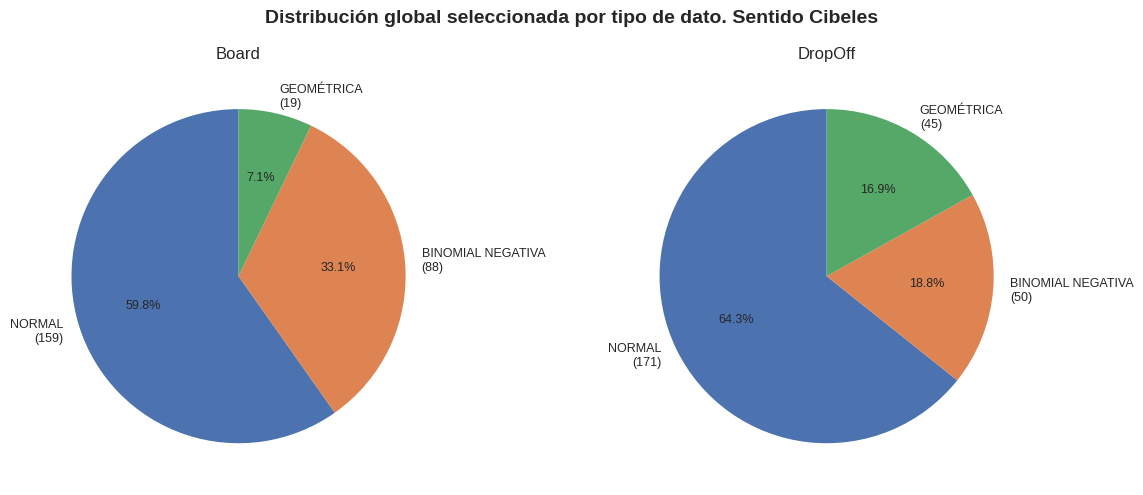

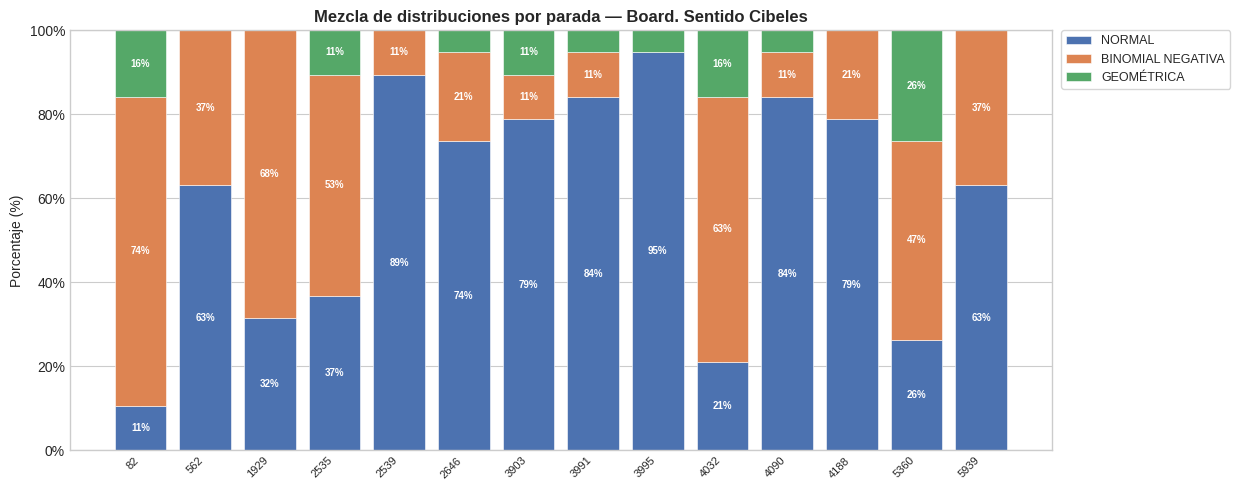

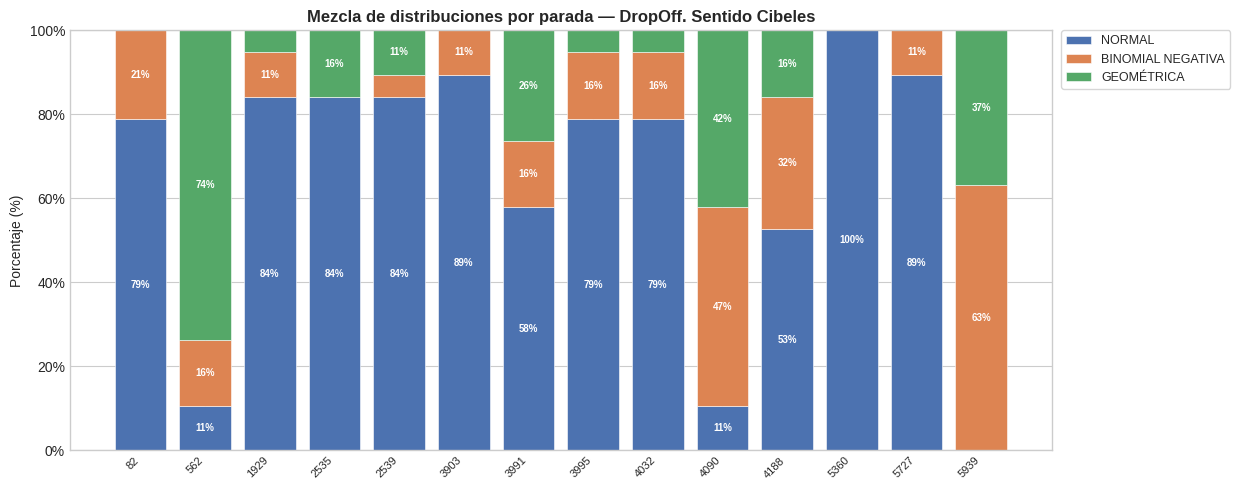

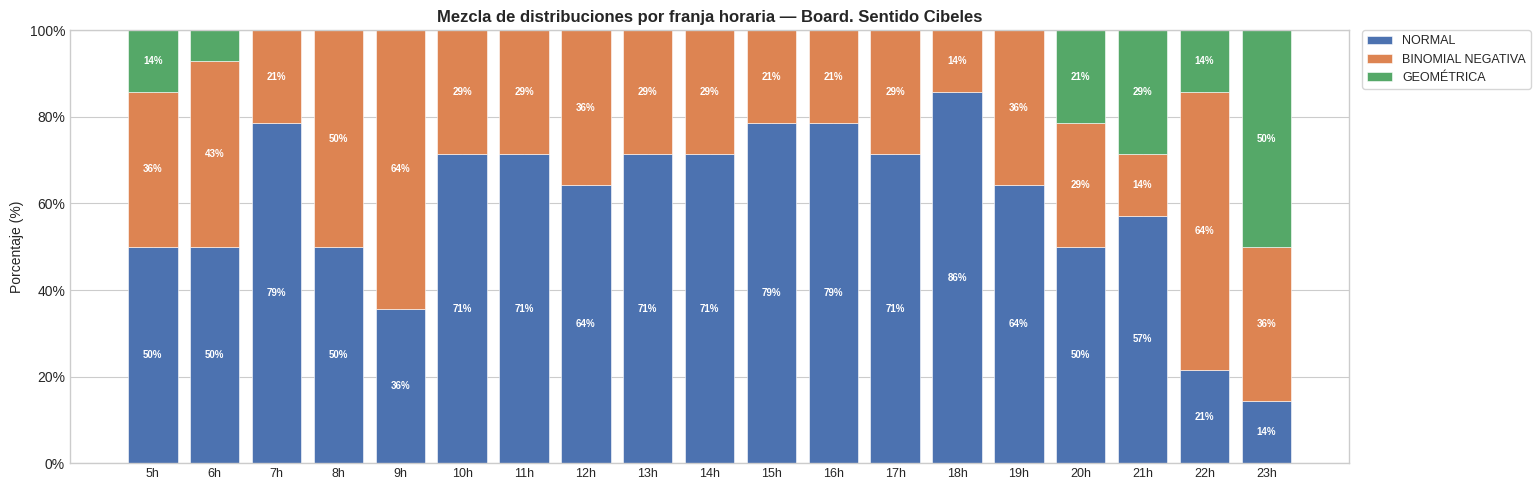

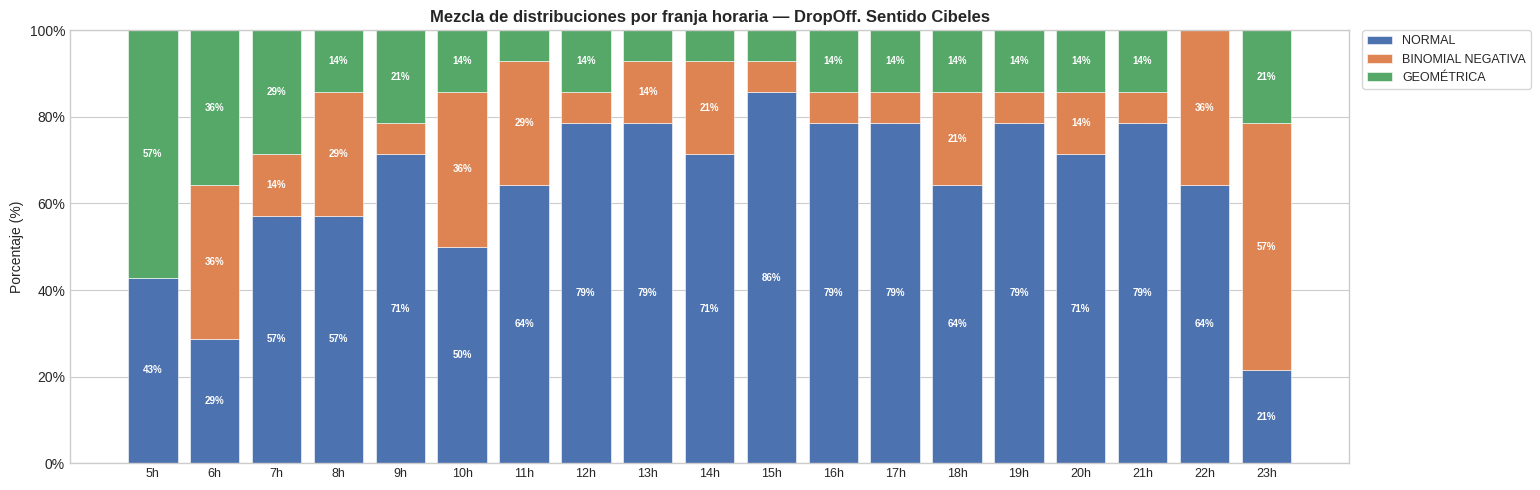

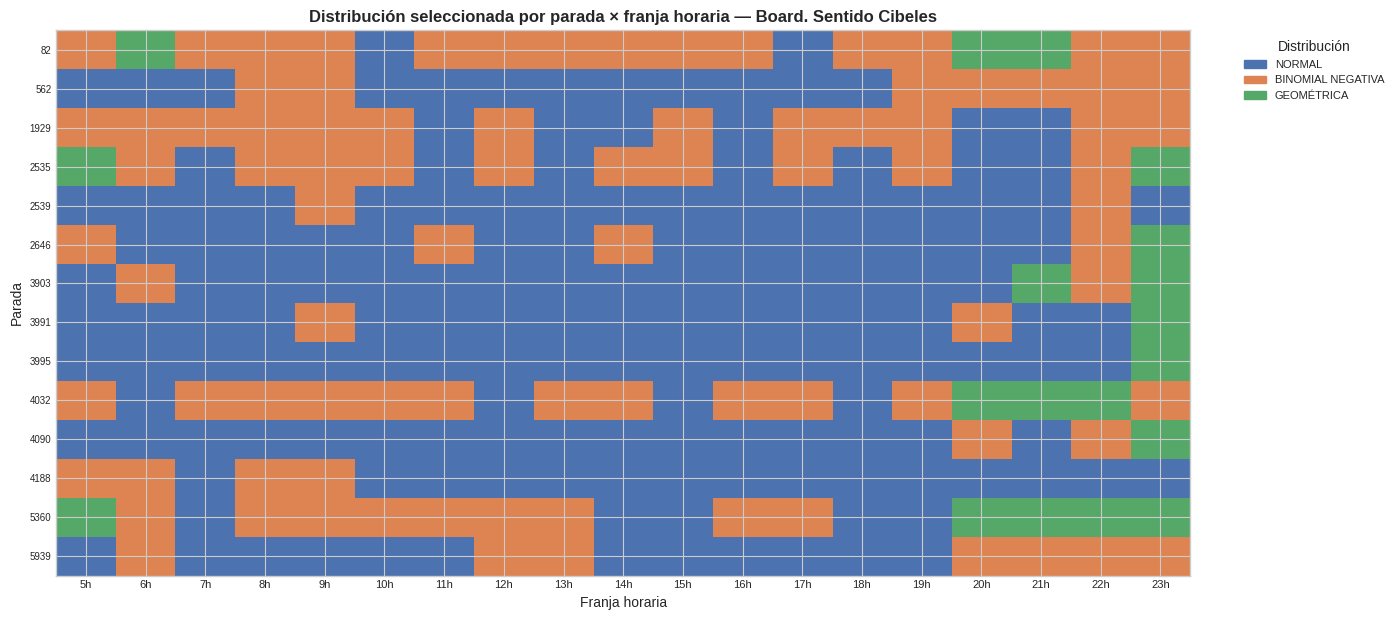

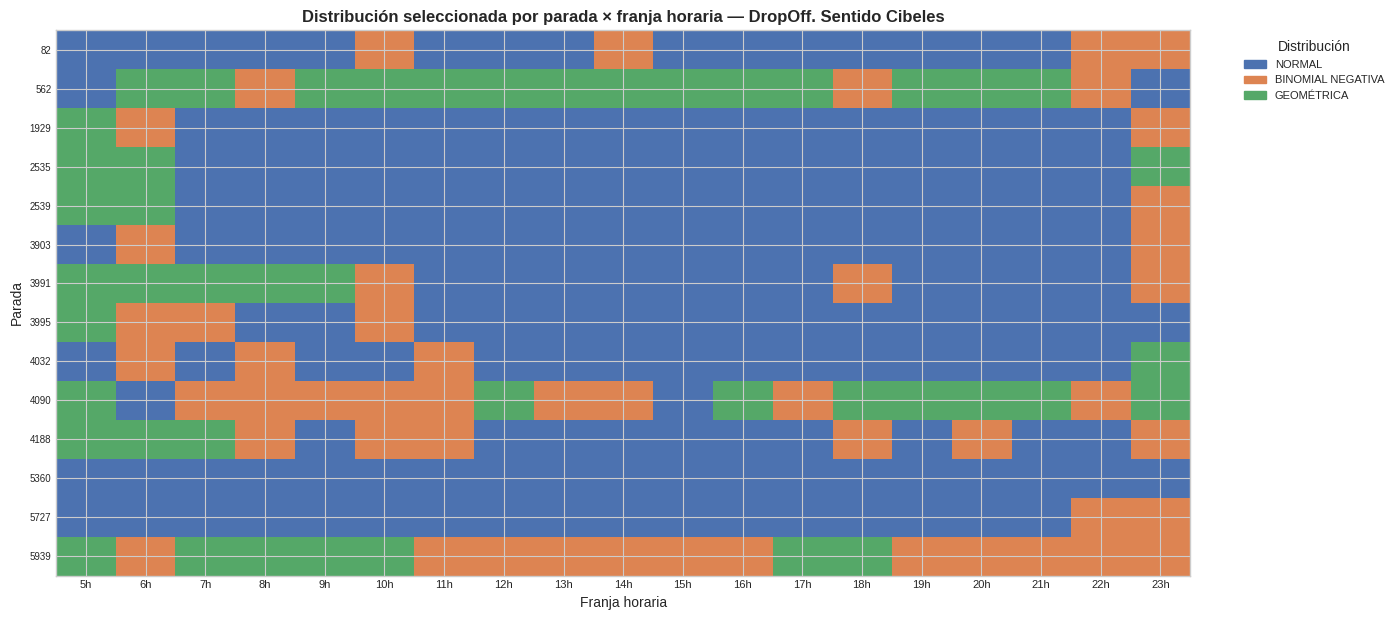

DataType  Stop  Total  NORMAL_%  BINOM_NEG_%  GEOMETRICA_%         Dominante
   Board    82     19      10.5         73.7          15.8 BINOMIAL NEGATIVA
   Board   562     19      63.2         36.8           0.0            NORMAL
   Board  1929     19      31.6         68.4           0.0 BINOMIAL NEGATIVA
   Board  2535     19      36.8         52.6          10.5 BINOMIAL NEGATIVA
   Board  2539     19      89.5         10.5           0.0            NORMAL
   Board  2646     19      73.7         21.1           5.3            NORMAL
   Board  3903     19      78.9         10.5          10.5            NORMAL
   Board  3991     19      84.2         10.5           5.3            NORMAL
   Board  3995     19      94.7          0.0           5.3            NORMAL
   Board  4032     19      21.1         63.2          15.8 BINOMIAL NEGATIVA
   Board  4090     19      84.2         10.5           5.3            NORMAL
   Board  4188     19      78.9         21.1           0.0            NORMAL

In [16]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap

# ─── Palette and helpers ──────────────────────────────────────────────────────
DIST_COLORS = {
    'NORMAL':            '#4C72B0',
    'BINOMIAL NEGATIVA': '#DD8452',
    'GEOMÉTRICA':        '#55A868',
}
# IMPORTANTE: en español, coincide exactamente con lo que guarda _record
DIST_NAMES = ['NORMAL', 'BINOMIAL NEGATIVA', 'GEOMÉTRICA']
TIMESLOTS  = [5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23]
DATA_TYPES = ['Board', 'DropOff']

def _pct(counts):
    total = sum(counts.values())
    if total == 0:
        return {d: 0.0 for d in DIST_NAMES}
    return {d: counts.get(d, 0) / total * 100 for d in DIST_NAMES}


# ═══════════════════════════════════════════════════════════════════════════════
# 1. GLOBAL PIE CHARTS
# ═══════════════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Distribución global seleccionada por tipo de dato. Sentido Cibeles",
             fontsize=14, fontweight='bold')

for ax, dt in zip(axes, DATA_TYPES):
    counts = distribution_global[dt]
    sizes  = [counts.get(d, 0) for d in DIST_NAMES]
    colors = [DIST_COLORS[d] for d in DIST_NAMES]
    labels = [f"{d}\n({counts.get(d, 0)})" for d in DIST_NAMES]

    ax.pie(sizes, labels=labels, colors=colors,
           autopct=lambda p: f'{p:.1f}%' if p > 0 else '',
           startangle=90, textprops={'fontsize': 9})
    ax.set_title(dt, fontsize=12)

plt.tight_layout()
plt.savefig("fig1_global_pie_toA.png", dpi=150, bbox_inches='tight')
plt.show()


# ═══════════════════════════════════════════════════════════════════════════════
# 2. PER-STOP STACKED BAR
# ═══════════════════════════════════════════════════════════════════════════════
for dt in DATA_TYPES:
    stops_with_data = sorted([s for s in distribution_counts[dt]
                               if sum(distribution_counts[dt][s].values()) > 0])
    n_stops = len(stops_with_data)
    if n_stops == 0:
        continue

    pcts = {d: [] for d in DIST_NAMES}
    for stop in stops_with_data:
        p = _pct(distribution_counts[dt][stop])
        for d in DIST_NAMES:
            pcts[d].append(p[d])

    x = np.arange(n_stops)
    fig, ax = plt.subplots(figsize=(max(10, n_stops * 0.6) + 2.5, 5))

    bottom = np.zeros(n_stops)
    for d in DIST_NAMES:
        bars = np.array(pcts[d])
        ax.bar(x, bars, bottom=bottom, label=d, color=DIST_COLORS[d],
               edgecolor='white', linewidth=0.4)
        for i, (b, v) in enumerate(zip(bottom, bars)):
            if v > 8:
                ax.text(i, b + v / 2, f'{v:.0f}%', ha='center', va='center',
                        fontsize=7, color='white', fontweight='bold')
        bottom += bars

    ax.set_xticks(x)
    ax.set_xticklabels([str(s) for s in stops_with_data], rotation=45, ha='right', fontsize=8)
    ax.set_ylabel("Porcentaje (%)")
    ax.set_ylim(0, 100)
    ax.set_title(f"Mezcla de distribuciones por parada — {dt}. Sentido Cibeles", fontweight='bold')
    ax.yaxis.set_major_formatter(mticker.PercentFormatter())
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), borderaxespad=0, fontsize=9, frameon=True)
    plt.tight_layout()
    plt.savefig(f"fig2_per_stop_{dt.lower()}_toA.png", dpi=150, bbox_inches='tight')
    plt.show()


# ═══════════════════════════════════════════════════════════════════════════════
# 3. PER-TIMESLOT STACKED BAR
# ═══════════════════════════════════════════════════════════════════════════════
timeslot_counts = {
    dt: {ts: {d: 0 for d in DIST_NAMES} for ts in TIMESLOTS}
    for dt in DATA_TYPES
}

for dt in DATA_TYPES:
    for stop, ts_dict in distribution_stats[dt].items():
        for ts, dist_name in ts_dict.items():
            if dist_name in DIST_NAMES:
                timeslot_counts[dt][ts][dist_name] += 1

for dt in DATA_TYPES:
    pcts = {d: [] for d in DIST_NAMES}
    for ts in TIMESLOTS:
        p = _pct(timeslot_counts[dt][ts])
        for d in DIST_NAMES:
            pcts[d].append(p[d])

    x = np.arange(len(TIMESLOTS))
    fig, ax = plt.subplots(figsize=(15.5, 5))

    bottom = np.zeros(len(TIMESLOTS))
    for d in DIST_NAMES:
        bars = np.array(pcts[d])
        ax.bar(x, bars, bottom=bottom, label=d, color=DIST_COLORS[d],
               edgecolor='white', linewidth=0.4)
        for i, (b, v) in enumerate(zip(bottom, bars)):
            if v > 8:
                ax.text(i, b + v / 2, f'{v:.0f}%', ha='center', va='center',
                        fontsize=7, color='white', fontweight='bold')
        bottom += bars

    ax.set_xticks(x)
    ax.set_xticklabels([f"{ts}h" for ts in TIMESLOTS], fontsize=9)
    ax.set_ylabel("Porcentaje (%)")
    ax.set_ylim(0, 100)
    ax.set_title(f"Mezcla de distribuciones por franja horaria — {dt}. Sentido Cibeles",
                 fontweight='bold')
    ax.yaxis.set_major_formatter(mticker.PercentFormatter())
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), borderaxespad=0, fontsize=9, frameon=True)
    plt.tight_layout()
    plt.savefig(f"fig3_per_timeslot_{dt.lower()}_toA.png", dpi=150, bbox_inches='tight')
    plt.show()


# ═══════════════════════════════════════════════════════════════════════════════
# 4. HEATMAP
# ═══════════════════════════════════════════════════════════════════════════════
DIST_TO_INT = {'NORMAL': 0, 'BINOMIAL NEGATIVA': 1, 'GEOMÉTRICA': 2}
INT_TO_DIST = {v: k for k, v in DIST_TO_INT.items()}
cmap = ListedColormap([DIST_COLORS[d] for d in DIST_NAMES])

for dt in DATA_TYPES:
    stops_with_data = sorted([s for s in distribution_stats[dt] if distribution_stats[dt][s]])

    matrix = np.full((len(stops_with_data), len(TIMESLOTS)), np.nan)
    for i, stop in enumerate(stops_with_data):
        for j, ts in enumerate(TIMESLOTS):
            dist = distribution_stats[dt][stop].get(ts, None)
            if dist in DIST_TO_INT:
                matrix[i, j] = DIST_TO_INT[dist]

    fig, ax = plt.subplots(figsize=(14, max(4, len(stops_with_data) * 0.45)))
    ax.imshow(matrix, aspect='auto', cmap=cmap, vmin=-0.5, vmax=2.5, interpolation='nearest')

    ax.set_xticks(np.arange(len(TIMESLOTS)))
    ax.set_xticklabels([f"{ts}h" for ts in TIMESLOTS], fontsize=8)
    ax.set_yticks(np.arange(len(stops_with_data)))
    ax.set_yticklabels([str(s) for s in stops_with_data], fontsize=7)
    ax.set_xlabel("Franja horaria")
    ax.set_ylabel("Parada")
    ax.set_title(f"Distribución seleccionada por parada × franja horaria — {dt}. Sentido Cibeles",
                 fontweight='bold')

    legend_patches = [Patch(color=DIST_COLORS[d], label=d) for d in DIST_NAMES]
    ax.legend(handles=legend_patches, loc='upper right', bbox_to_anchor=(1.18, 1),
              fontsize=8, title="Distribución")
    plt.tight_layout()
    plt.savefig(f"fig4_heatmap_{dt.lower()}_toA.png", dpi=150, bbox_inches='tight')
    plt.show()


# ═══════════════════════════════════════════════════════════════════════════════
# 5. SUMMARY TABLES
# ═══════════════════════════════════════════════════════════════════════════════
rows = []
for dt in DATA_TYPES:
    for stop in sorted(distribution_counts[dt].keys()):
        counts = distribution_counts[dt][stop]
        total  = sum(counts.values())
        if total == 0:
            continue
        p = _pct(counts)
        dominant = max(counts, key=counts.get)
        rows.append({
            'DataType':        dt,
            'Stop':            stop,
            'Total':           total,
            'NORMAL_%':        round(p['NORMAL'], 1),
            'BINOM_NEG_%':     round(p['BINOMIAL NEGATIVA'], 1),
            'GEOMETRICA_%':    round(p['GEOMÉTRICA'], 1),
            'Dominante':       dominant,
        })

summary_df = pd.DataFrame(rows)
print(summary_df.to_string(index=False))
summary_df.to_csv("distribution_summary_per_stop_toA.csv", index=False)

rows_ts = []
for dt in DATA_TYPES:
    for ts in TIMESLOTS:
        counts = timeslot_counts[dt][ts]
        total  = sum(counts.values())
        if total == 0:
            continue
        p = _pct(counts)
        dominant = max(counts, key=counts.get)
        rows_ts.append({
            'DataType':     dt,
            'Timeslot':     ts,
            'Total':        total,
            'NORMAL_%':     round(p['NORMAL'], 1),
            'BINOM_NEG_%':  round(p['BINOMIAL NEGATIVA'], 1),
            'GEOMETRICA_%': round(p['GEOMÉTRICA'], 1),
            'Dominante':    dominant,
        })

timeslot_summary_df = pd.DataFrame(rows_ts)
print(timeslot_summary_df.to_string(index=False))
timeslot_summary_df.to_csv("distribution_summary_per_timeslot_toA.csv", index=False)